# Seasonal Shadow Targets at Amundsen Crater for Diviner Observations

**Model:** PTM3D v2 — 4M-face LOLA DEM mesh, SPICE ephemeris, Embree ray tracing, H-matrix radiation exchange  
**Mesh:** LDEM_80S_20M polar DEM, ~20 m resolution, Delaunay triangulation with adaptive radial refinement  
**Period:** April 2026 – March 2028 (25 lunations)

---

## Objective

Identify locations at the margin of the permanently shadowed region (PSR) in Amundsen crater that transition between illuminated and shadowed states over the lunar year. These seasonally shadowed targets are candidates for timed Diviner observations of the thermal response to seasonal illumination changes.

From a 25-lunation illumination survey we classify every mesh face and identify seasonally shadowed clusters — regions that are dark for 12+ consecutive lunations but illuminated during the remainder. For the best targets, we provide illumination and temperature time series with UTC timing for observation planning.

In [1]:
import sys, struct, warnings
from pathlib import Path
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap, BoundaryNorm
import pyvista as pv

warnings.filterwarnings('ignore', category=DeprecationWarning)
pv.set_jupyter_backend('static')
pv.global_theme.background = 'white'
pv.global_theme.font.color = 'black'

# --- Paths ---
BASE = Path("/Users/paha3326/Library/CloudStorage/OneDrive-UCB-O365/europa/heat3d/ptm")
SURVEY_DIR = BASE / "output/survey"
THERMAL_DIR = BASE / "output/thermal"
MESH_PLY = THERMAL_DIR / "lunation_07/mesh.ply"
LOCATIONS_CSV = BASE / "configs/amundsen_target_locations.csv"
CLASSIFICATION_BIN = SURVEY_DIR / "face_classification.bin"
TIMESERIES_CSV = THERMAL_DIR / "amundsen_seasonal_timeseries.csv"
FIG_DIR = BASE / "plots/amundsen_report"
FIG_DIR.mkdir(parents=True, exist_ok=True)

NUM_LUNATIONS = 23
SUMMER_LUNATION = 7   # Oct 2026 — peak illumination
WINTER_LUNATION = 13  # Apr 2027 — minimum illumination
LUNATION_DAYS = 29.530588

# Matplotlib defaults
plt.rcParams.update({
    'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 13,
    'figure.dpi': 150, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'figure.facecolor': 'white',
})

print("Setup complete.")

Setup complete.


In [2]:
# --- Utility functions (from scripts/identify_seasonal_shadow.py) ---

def parse_ply_header(f):
    """Parse binary PLY header."""
    format_type, num_vertices, num_faces = 'ascii', 0, 0
    vertex_props, face_props = [], []
    current_element = None
    while True:
        line = f.readline().decode('ascii').strip()
        if line == 'end_header':
            break
        parts = line.split()
        if not parts:
            continue
        if parts[0] == 'format':
            format_type = parts[1]
        elif parts[0] == 'element':
            current_element = parts[1]
            if current_element == 'vertex':
                num_vertices = int(parts[2])
            elif current_element == 'face':
                num_faces = int(parts[2])
        elif parts[0] == 'property':
            if current_element == 'vertex' and len(parts) >= 3:
                vertex_props.append((parts[1], parts[2]))
            elif current_element == 'face':
                if parts[1] == 'list':
                    face_props.append(('list',))
                else:
                    face_props.append((parts[1], parts[2]))
    return {'format': format_type, 'num_vertices': num_vertices,
            'num_faces': num_faces, 'vertex_props': vertex_props,
            'face_props': face_props}


def read_ply_mesh(file_path):
    """Read binary PLY mesh → vertices, faces, face_centers, latitudes, longitudes."""
    with open(file_path, 'rb') as f:
        hdr = parse_ply_header(f)
        nv, nf = hdr['num_vertices'], hdr['num_faces']
        endian = '<' if hdr['format'] == 'binary_little_endian' else '>'
        # Vertex dtype
        vfmt = []
        bpv = 0
        for pt, pn in hdr['vertex_props']:
            if pt == 'float':
                vfmt.append(('f4', pn)); bpv += 4
            elif pt == 'double':
                vfmt.append(('f8', pn)); bpv += 8
        vdtype = np.dtype([(name, endian + dt) for dt, name in vfmt])
        va = np.frombuffer(f.read(nv * bpv), dtype=vdtype)
        vertices = np.column_stack([va[ax] for ax in 'xyz']).astype(np.float64)
        # Check for face lat/lon
        has_ll = any(len(p) == 2 and p[1] == 'latitude' for p in hdr['face_props'])
        faces = np.zeros((nf, 3), dtype=np.int32)
        lat_f = np.zeros(nf, np.float64) if has_ll else None
        lon_f = np.zeros(nf, np.float64) if has_ll else None
        for i in range(nf):
            cnt = struct.unpack('B', f.read(1))[0]
            idx = struct.unpack(f'{endian}{cnt}I', f.read(cnt * 4))
            faces[i] = idx[:3]
            if has_ll:
                lat_f[i] = struct.unpack(endian + 'f', f.read(4))[0]
                lon_f[i] = struct.unpack(endian + 'f', f.read(4))[0]
    fc = (vertices[faces[:, 0]] + vertices[faces[:, 1]] + vertices[faces[:, 2]]) / 3.0
    if lat_f is not None:
        return vertices, faces, fc, lat_f, lon_f
    x, y, z = fc[:, 0], fc[:, 1], fc[:, 2]
    r = np.sqrt(x**2 + y**2 + z**2)
    return vertices, faces, fc, np.degrees(np.arcsin(z / r)), np.degrees(np.arctan2(y, x))


def read_stats_binary(filepath):
    """Read binary stats file: uint32 count + float32 array."""
    with open(filepath, 'rb') as f:
        count = struct.unpack('<I', f.read(4))[0]
        return np.frombuffer(f.read(count * 4), dtype=np.float32)


def read_classification_binary(filepath):
    """Read face classification: uint32 count + uint8 array."""
    with open(filepath, 'rb') as f:
        count = struct.unpack('<I', f.read(4))[0]
        return np.frombuffer(f.read(count), dtype=np.uint8)


def read_locations_csv(filepath):
    """Read target locations CSV → list of dicts."""
    locs = []
    with open(filepath) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            parts = line.split(',')
            if len(parts) >= 3:
                locs.append({'name': parts[0].strip(),
                             'lat': float(parts[1]), 'lon': float(parts[2])})
    return locs


print(f"Utility functions defined.")

Utility functions defined.


In [3]:
# --- Load mesh (takes ~30s for 4M faces) ---
print("Loading mesh...")
vertices, faces, face_centers, latitudes, longitudes = read_ply_mesh(str(MESH_PLY))
nf = len(faces)
print(f"  {len(vertices):,} vertices, {nf:,} faces")

# Construct PyVista PolyData (reused for all 3D figures)
faces_pv = np.column_stack([np.full(nf, 3), faces]).ravel().astype(np.int64)
mesh_pv = pv.PolyData(vertices.astype(np.float32), faces_pv)
print(f"  PyVista mesh: {mesh_pv.n_points:,} points, {mesh_pv.n_cells:,} cells")

Loading mesh...


  2,001,149 vertices, 4,000,999 faces


  PyVista mesh: 2,001,149 points, 4,000,999 cells


In [4]:
# --- Load all data ---
classification = read_classification_binary(str(CLASSIFICATION_BIN))
locations_csv = read_locations_csv(str(LOCATIONS_CSV))

# Per-face illumination duration maps (from compute_illumination_duration.py)
illum_fraction = read_stats_binary(str(SURVEY_DIR / "illum_total_fraction.bin"))
max_continuous_hours = read_stats_binary(str(SURVEY_DIR / "illum_max_continuous_hours.bin"))

# Summer and winter per-face statistics
summer_solar = read_stats_binary(str(THERMAL_DIR / "lunation_07/statistics/direct_solar_avg.bin"))
winter_solar = read_stats_binary(str(THERMAL_DIR / "lunation_13/statistics/direct_solar_avg.bin"))
summer_temp = read_stats_binary(str(THERMAL_DIR / "lunation_07/statistics/temperature_avg.bin"))
winter_temp = read_stats_binary(str(THERMAL_DIR / "lunation_13/statistics/temperature_avg.bin"))
summer_temp_max = read_stats_binary(str(THERMAL_DIR / "lunation_07/statistics/temperature_max.bin"))

# Wilcoski candidate site
wilcoski_lat, wilcoski_lon = -83.93341, 92.51474
wilcoski_fidx = int(np.argmin((latitudes - wilcoski_lat)**2 + (longitudes - wilcoski_lon)**2))

# ========== SITE SELECTION (adjustable parameters) ==========
MIN_CONTINUOUS_HOURS = 8.0     # minimum continuous illumination window
MAX_TEMPERATURE_K = 150.0      # maximum temperature (summer lunation)
MAX_ILLUM_FRACTION = 0.20      # upper bound on illumination fraction
MIN_ILLUM_FRACTION = 0.0001    # lower bound (exclude PSR)

candidates_mask = (
    (illum_fraction > MIN_ILLUM_FRACTION) &
    (illum_fraction < MAX_ILLUM_FRACTION) &
    (max_continuous_hours >= MIN_CONTINUOUS_HOURS) &
    (summer_temp_max < MAX_TEMPERATURE_K)
)

n_candidates = np.sum(candidates_mask)
print(f"=== Site Selection ===")
print(f"  Criteria: {MIN_ILLUM_FRACTION*100:.2f}% < illum < {MAX_ILLUM_FRACTION*100:.0f}%, "
      f"continuous >= {MIN_CONTINUOUS_HOURS:.0f} hr, T_max < {MAX_TEMPERATURE_K:.0f} K")
print(f"  Candidate faces: {n_candidates:,} ({100*n_candidates/nf:.2f}%)")
print(f"  PSR (frac=0): {np.sum(illum_fraction==0):,}")
print(f"  Illum fraction range: {illum_fraction.min():.4f} – {illum_fraction.max():.4f}")
print(f"  Max continuous range: {max_continuous_hours.min():.0f} – {max_continuous_hours.max():.0f} hr")

# Build locations from candidate faces (cluster and pick representative)
# Group candidates into connected clusters via adjacency
from collections import deque, defaultdict

def build_adjacency_fast(faces, nf):
    edge_to_faces = defaultdict(list)
    for fi in range(nf):
        v = tuple(sorted(faces[fi]))
        for e in [(v[0],v[1]), (v[0],v[2]), (v[1],v[2])]:
            edge_to_faces[e].append(fi)
    adj = [[] for _ in range(nf)]
    for fl in edge_to_faces.values():
        for i in range(len(fl)):
            for j in range(i+1, len(fl)):
                adj[fl[i]].append(fl[j])
                adj[fl[j]].append(fl[i])
    return adj

def cluster_faces_bfs(face_indices, adj):
    face_set = set(face_indices)
    visited = set()
    clusters = []
    for fi in face_indices:
        if fi in visited: continue
        cluster = []
        q = deque([fi]); visited.add(fi)
        while q:
            node = q.popleft(); cluster.append(node)
            for nb in adj[node]:
                if nb in face_set and nb not in visited:
                    visited.add(nb); q.append(nb)
        clusters.append(cluster)
    return clusters

print("Building adjacency for candidate clustering...")
adj = build_adjacency_fast(faces, nf)
candidate_indices = np.where(candidates_mask)[0].tolist()
clusters = cluster_faces_bfs(candidate_indices, adj)
clusters = [c for c in clusters if len(c) >= 50]  # minimum 50 faces per cluster (~1 km² at 20m)
clusters.sort(key=len, reverse=True)
print(f"  Clusters (>=50 faces): {len(clusters)}")

# Select representative face per cluster: the one with longest continuous illumination
locations = []
for ci, cluster in enumerate(clusters[:50]):  # top 50 clusters
    arr = np.array(cluster)
    best = arr[np.argmax(max_continuous_hours[arr])]
    lat, lon = latitudes[best], longitudes[best]
    locations.append({
        'name': f"Site_{ci:03d}_{len(cluster)}f",
        'lat': lat, 'lon': lon, 'face_idx': int(best),
        'cluster_size': len(cluster),
        'illum_frac': float(illum_fraction[best]),
        'max_cont_hrs': float(max_continuous_hours[best]),
        'summer_tmax': float(summer_temp_max[best]),
        'is_prime': True,  # all candidates meet criteria
    })

prime_targets = locations  # all are prime by construction
print(f"  Selected sites: {len(locations)}")

# Lunation dates and time series
lunation_dates = [datetime(2026, 4, 1) + timedelta(days=i * LUNATION_DAYS) for i in range(NUM_LUNATIONS)]

# Load time series if available
try:
    df_ts = pd.read_csv(str(TIMESERIES_CSV), comment='#')
    df_ts['Time'] = pd.to_datetime(df_ts['Time'])
    print(f"  Time series: {len(df_ts)} timesteps")
except:
    df_ts = None
    print(f"  Time series: not available (locations changed)")

=== Site Selection ===
  Criteria: 0.01% < illum < 20%, continuous >= 8 hr, T_max < 150 K
  Candidate faces: 57,855 (1.45%)
  PSR (frac=0): 269,112
  Illum fraction range: 0.0000 – 0.5383
  Max continuous range: 0 – 3341 hr
Building adjacency for candidate clustering...


  Clusters (>=50 faces): 50
  Selected sites: 50
  Time series: 720 timesteps


## 1. Shadow Classification and Illumination Maps

### 1a. Face Classification
Three-class map: **PSR** (blue, never illuminated), **seasonally shadowed** (orange), **always illuminated** (gray). Red markers show selected observation targets.

### 1b. Illumination Fraction
Fraction of total time each face is illuminated over the 2-year survey, accounting for diurnal and seasonal cycles.

### 1c. Longest Continuous Illumination
Maximum duration (hours) of uninterrupted direct solar illumination at each face. This is the key metric for determining whether a face has an illumination window long enough for Diviner observation (minimum 8 hours).

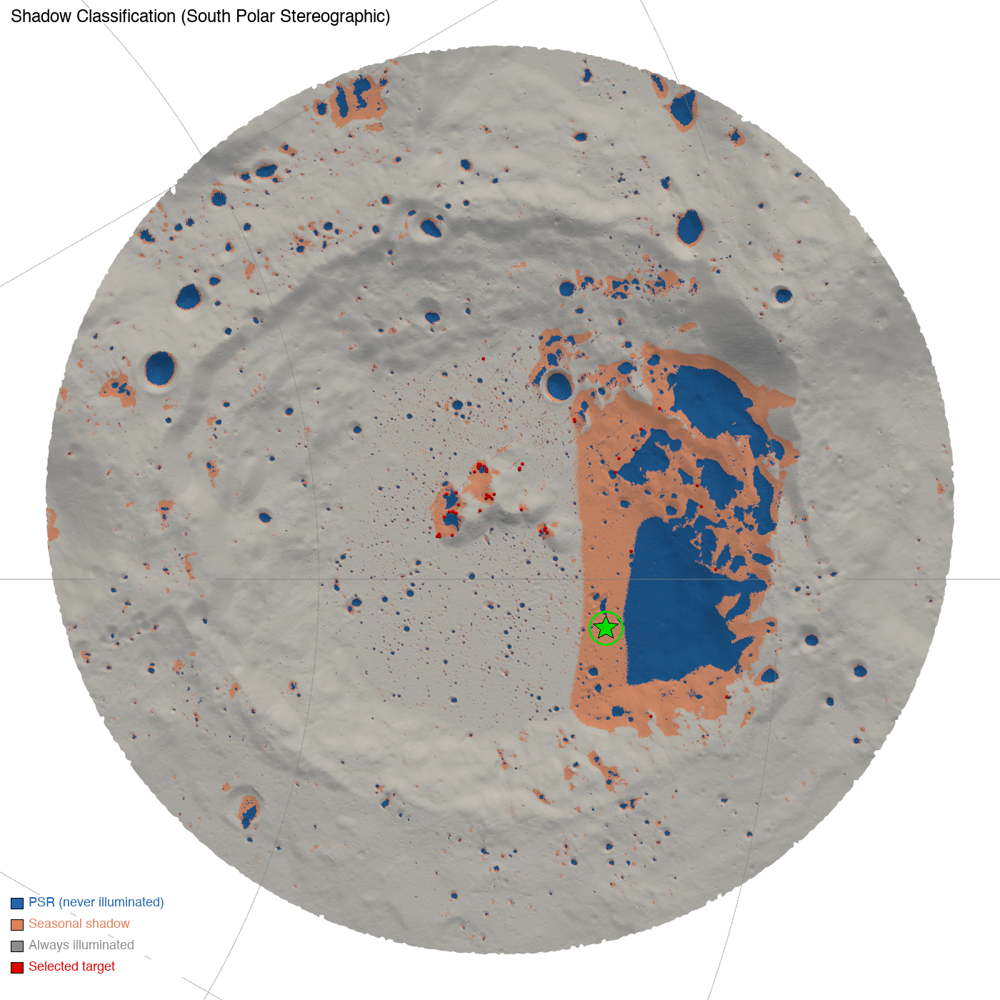

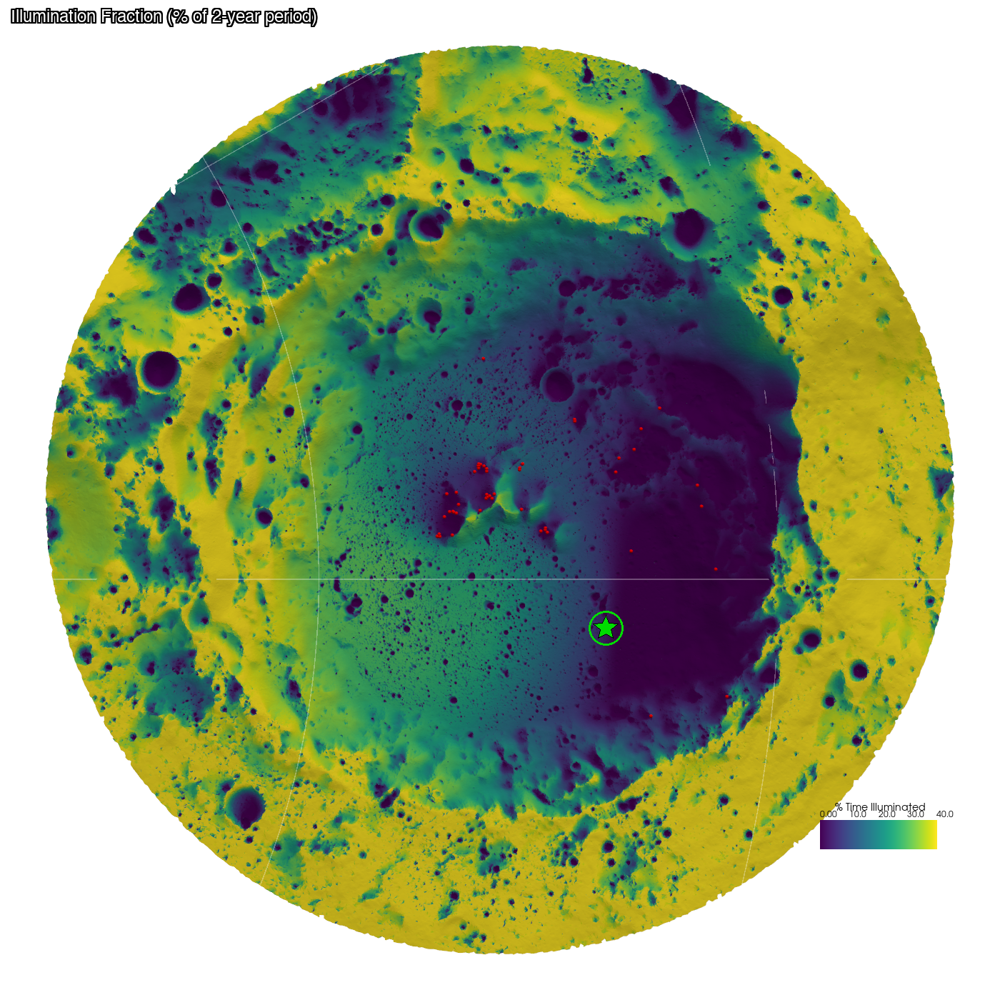

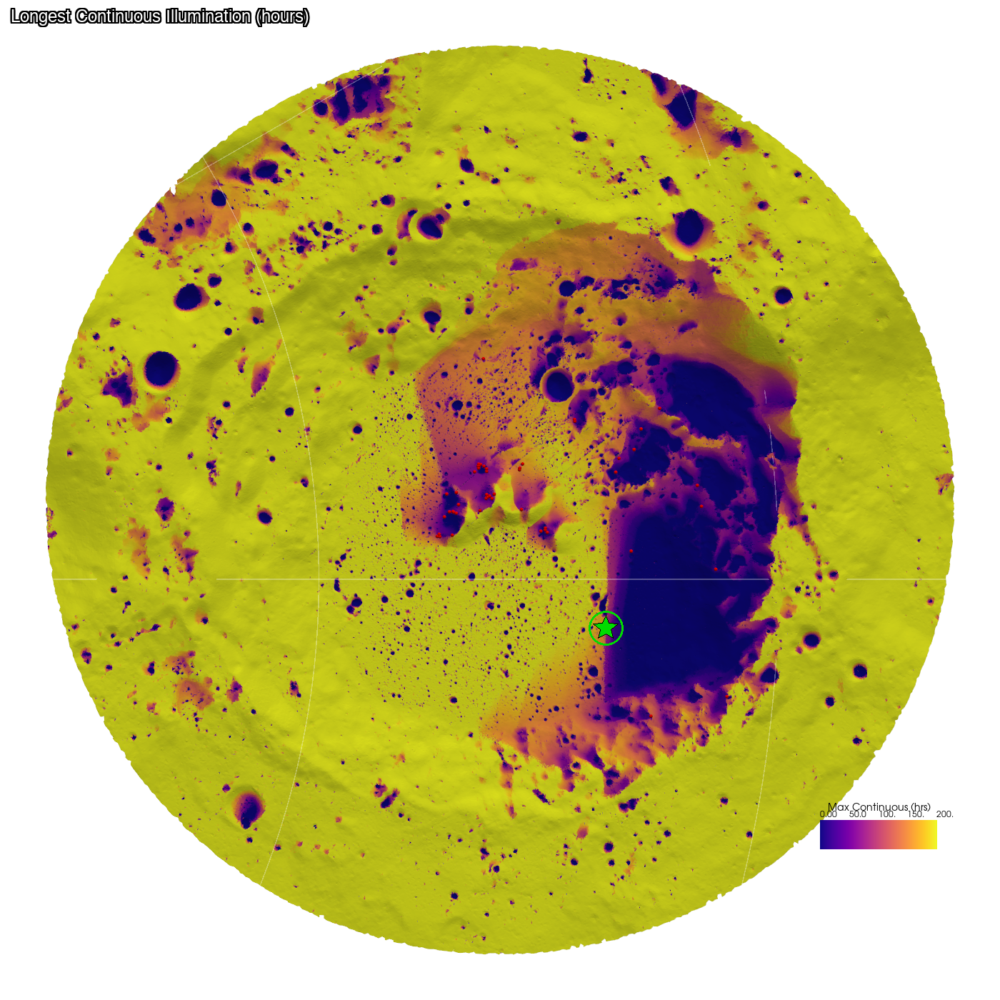

In [5]:
# --- Helper functions for stereographic projection ---
from PIL import Image, ImageDraw, ImageFont

def make_stereo_mesh(verts, faces, nf):
    R = 1737400.0
    v_r = np.sqrt(np.sum(verts**2, axis=1))
    v_lat = np.arcsin(verts[:, 2] / v_r)
    v_lon = np.arctan2(verts[:, 1], verts[:, 0])
    v_k = 2.0 * R * np.tan(np.pi/4.0 + v_lat/2.0)
    v_sx = v_k * np.sin(v_lon)
    v_sy = v_k * np.cos(v_lon)
    v_sz = (v_r - R).astype(np.float32)
    sp_verts = np.column_stack([v_sx, v_sy, v_sz]).astype(np.float32)
    faces_pv_arr = np.column_stack([np.full(nf, 3), faces]).ravel().astype(np.int64)
    return pv.PolyData(sp_verts, faces_pv_arr), v_sx, v_sy

def stereo_camera(sp_mesh):
    return [(sp_mesh.center[0], sp_mesh.center[1], 50000),
            (sp_mesh.center[0], sp_mesh.center[1], 0), (0, 1, 0)]

def add_latlon_grid(pl, R_m=1737400.0, lat_step=2.5, lon_step=30,
                    lat_range=(-88, -80), color='gray', opacity=0.4, width=1.5):
    """Add lat/lon grid lines only (labels added via PIL post-processing)."""
    for lon_deg in np.arange(0, 360, lon_step):
        lon_rad = np.radians(lon_deg)
        lat_pts = np.linspace(np.radians(lat_range[0]), np.radians(lat_range[1]), 100)
        k = 2.0 * R_m * np.tan(np.pi/4.0 + lat_pts/2.0)
        pts = np.column_stack([k*np.sin(lon_rad), k*np.cos(lon_rad), np.zeros(100)+50])
        pl.add_mesh(pv.Spline(pts, n_points=100), color=color, opacity=opacity, line_width=width)
    for lat_deg in np.arange(lat_range[0], lat_range[1]+0.1, lat_step):
        lat_rad = np.radians(lat_deg)
        lon_pts = np.linspace(0, 2*np.pi, 360)
        k = 2.0 * R_m * np.tan(np.pi/4.0 + lat_rad/2.0)
        pts = np.column_stack([k*np.sin(lon_pts), k*np.cos(lon_pts), np.zeros(360)+50])
        pl.add_mesh(pv.Spline(pts, n_points=360), color=color, opacity=opacity, line_width=width)

def setup_stereo_view(pl, sp_mesh, sp_x, sp_y):
    pl.camera_position = stereo_camera(sp_mesh)
    pl.camera.parallel_projection = True
    pl.camera.parallel_scale = max(sp_x.max()-sp_x.min(), sp_y.max()-sp_y.min()) * 0.55

def _draw_outlined_text(draw, pos, text, fill, font, outline_color=(0,0,0), outline_width=2):
    """Draw text with a dark outline for readability on any background."""
    x, y = pos
    for dx in range(-outline_width, outline_width+1):
        for dy in range(-outline_width, outline_width+1):
            if dx != 0 or dy != 0:
                draw.text((x+dx, y+dy), text, fill=outline_color, font=font)
    draw.text((x, y), text, fill=fill, font=font)

def annotate_grid_labels(img_path, sp_x, sp_y, R_m=1737400.0,
                         lat_range=(-88, -80), lat_step=2.5, lon_step=30,
                         text_color=(255,255,255), title=None, title_color=(0,0,0),
                         legend=None):
    """Add lat/lon labels, title, and legend to a PyVista screenshot using PIL."""
    img = Image.open(img_path)
    draw = ImageDraw.Draw(img)
    W, H = img.size

    scale = max(sp_x.max()-sp_x.min(), sp_y.max()-sp_y.min()) * 0.55
    cx_s = (sp_x.min()+sp_x.max())/2
    cy_s = (sp_y.min()+sp_y.max())/2

    def stereo_to_pixel(sx, sy):
        px = W/2 + (sx - cx_s) / (2*scale) * W
        py = H/2 - (sy - cy_s) / (2*scale) * H
        return int(px), int(py)

    try:
        font = ImageFont.truetype("/System/Library/Fonts/Helvetica.ttc", 20)
        font_sm = ImageFont.truetype("/System/Library/Fonts/Helvetica.ttc", 17)
        font_title = ImageFont.truetype("/System/Library/Fonts/Helvetica.ttc", 24)
        font_legend = ImageFont.truetype("/System/Library/Fonts/Helvetica.ttc", 18)
    except:
        font = font_sm = font_title = font_legend = ImageFont.load_default()

    # Outline color: opposite of text for contrast
    outline = (0,0,0) if sum(text_color) > 380 else (255,255,255)

    # Longitude labels at outer edge
    for lon_deg in range(0, 360, lon_step):
        lon_rad = np.radians(lon_deg)
        label_lat = np.radians(lat_range[1])
        k = 2.0 * R_m * np.tan(np.pi/4.0 + label_lat/2.0) * 1.07
        sx = k * np.sin(lon_rad)
        sy = k * np.cos(lon_rad)
        px, py = stereo_to_pixel(sx, sy)
        if 20 < px < W-20 and 20 < py < H-20:
            _draw_outlined_text(draw, (px-18, py-10), f"{lon_deg}°",
                                fill=text_color, font=font_sm, outline_color=outline)

    # Latitude labels along 45° longitude
    for lat_deg in np.arange(lat_range[0], lat_range[1]+0.1, lat_step):
        lat_rad = np.radians(lat_deg)
        lon_rad = np.radians(45)
        k = 2.0 * R_m * np.tan(np.pi/4.0 + lat_rad/2.0)
        sx = k * np.sin(lon_rad)
        sy = k * np.cos(lon_rad)
        px, py = stereo_to_pixel(sx, sy)
        if 20 < px < W-50 and 20 < py < H-20:
            _draw_outlined_text(draw, (px+8, py-10), f"{int(lat_deg)}°S",
                                fill=text_color, font=font_sm, outline_color=outline)

    # Title
    if title:
        t_outline = (255,255,255) if sum(title_color) < 380 else (0,0,0)
        _draw_outlined_text(draw, (15, 12), title,
                            fill=title_color, font=font_title, outline_color=t_outline)

    # Legend
    if legend:
        y0 = H - 25 - len(legend) * 30
        for i, (label, color_rgb) in enumerate(legend):
            y = y0 + i * 30
            # Draw background rectangle for readability
            draw.rectangle([10, y-2, 300, y+22], fill=(255,255,255,200))
            draw.rectangle([15, y+2, 32, y+17], fill=color_rgb, outline=(0,0,0))
            draw.text((40, y), label, fill=color_rgb, font=font_legend)

    # Draw Wilcoski site marker (green star + circle)
    _wk = 2.0 * R_m * np.tan(np.pi/4.0 + np.radians(-83.93341)/2.0)
    _wpx, _wpy = stereo_to_pixel(_wk * np.sin(np.radians(92.51474)), _wk * np.cos(np.radians(92.51474)))
    if 10 < _wpx < W-10 and 10 < _wpy < H-10:
        _pts = []
        for _ks in range(10):
            _ang = _ks * np.pi / 5 - np.pi/2
            _rs = 18 if _ks % 2 == 0 else 8
            _pts.append((_wpx + _rs*np.cos(_ang), _wpy + _rs*np.sin(_ang)))
        draw.polygon(_pts, fill=(0, 220, 0), outline=(0, 0, 0))
        draw.ellipse([_wpx-24, _wpy-24, _wpx+24, _wpy+24], outline=(0, 220, 0), width=3)

    img.save(img_path)


sp_mesh, sp_x_verts, sp_y_verts = make_stereo_mesh(vertices, faces, nf)
R_m = 1737400.0
fc_lat_rad, fc_lon_rad = np.radians(latitudes), np.radians(longitudes)
fc_k = 2.0 * R_m * np.tan(np.pi/4.0 + fc_lat_rad/2.0)
sp_x, sp_y = fc_k * np.sin(fc_lon_rad), fc_k * np.cos(fc_lon_rad)

def add_site_markers(pl, locs, sp_x, sp_y):
    for loc in locs:
        fi = loc['face_idx']
        pl.add_mesh(pv.Sphere(radius=300, center=(float(sp_x[fi]), float(sp_y[fi]), 300)),
                    color='red')

# --- Fig 1a: Classification ---
cmap_class = ListedColormap(['#2166ac', '#f4a582', '#d9d9d9'])
sp_mesh.cell_data['classification'] = classification
pl = pv.Plotter(off_screen=True, window_size=[1400, 1400])
pl.add_mesh(sp_mesh, scalars='classification', cmap=cmap_class, clim=[-0.5, 2.5],
            show_scalar_bar=False, smooth_shading=False)
add_site_markers(pl, locations, sp_x, sp_y)
add_latlon_grid(pl)
setup_stereo_view(pl, sp_mesh, sp_x, sp_y)
fig1_path = str(FIG_DIR / 'fig1_classification.png')
pl.screenshot(fig1_path)
pl.close()
annotate_grid_labels(fig1_path, sp_x, sp_y,
    text_color=(60, 60, 60), title="Shadow Classification (South Polar Stereographic)",
    title_color=(0, 0, 0),
    legend=[
        ("PSR (never illuminated)", (33, 102, 172)),
        ("Seasonal shadow", (220, 130, 90)),
        ("Always illuminated", (140, 140, 140)),
        ("Selected target", (220, 0, 0)),
    ])
from IPython.display import display, Image as IPImage
display(IPImage(filename=fig1_path))

# --- Fig 1b: Illumination Fraction ---
sp_mesh_frac = sp_mesh.copy()
sp_mesh_frac.cell_data['illum_frac'] = illum_fraction * 100
pl = pv.Plotter(off_screen=True, window_size=[1400, 1400])
pl.add_mesh(sp_mesh_frac, scalars='illum_frac', cmap='viridis', clim=[0, 40],
            scalar_bar_args={'title': '% Time Illuminated', 'color': 'black',
                             'title_font_size': 14, 'label_font_size': 12,
                             'position_x': 0.82, 'position_y': 0.15, 'width': 0.12},
            smooth_shading=False)
add_site_markers(pl, locations, sp_x, sp_y)
add_latlon_grid(pl, color='white', opacity=0.3)
setup_stereo_view(pl, sp_mesh, sp_x, sp_y)
fig1b_path = str(FIG_DIR / 'fig1b_illum_fraction.png')
pl.screenshot(fig1b_path)
pl.close()
annotate_grid_labels(fig1b_path, sp_x, sp_y, text_color=(255,255,255),
    title="Illumination Fraction (% of 2-year period)", title_color=(255,255,255))
display(IPImage(filename=fig1b_path))

# --- Fig 1c: Max Continuous Illumination Duration ---
sp_mesh_dur = sp_mesh.copy()
dur_clipped = np.minimum(max_continuous_hours, 200.0)
sp_mesh_dur.cell_data['max_cont_hrs'] = dur_clipped
pl = pv.Plotter(off_screen=True, window_size=[1400, 1400])
pl.add_mesh(sp_mesh_dur, scalars='max_cont_hrs', cmap='plasma', clim=[0, 200],
            scalar_bar_args={'title': 'Max Continuous (hrs)', 'color': 'black',
                             'title_font_size': 14, 'label_font_size': 12,
                             'position_x': 0.82, 'position_y': 0.15, 'width': 0.12},
            smooth_shading=False)
add_site_markers(pl, locations, sp_x, sp_y)
add_latlon_grid(pl, color='white', opacity=0.3)
setup_stereo_view(pl, sp_mesh, sp_x, sp_y)
fig1c_path = str(FIG_DIR / 'fig1c_continuous_duration.png')
pl.screenshot(fig1c_path)
pl.close()
annotate_grid_labels(fig1c_path, sp_x, sp_y, text_color=(255,255,255),
    title="Longest Continuous Illumination (hours)", title_color=(255,255,255))
display(IPImage(filename=fig1c_path))



## 2. Summer Direct Solar Illumination

Average direct solar flux during the summer lunation (Lunation 07, October 2026). The illuminated crater walls and floor show which areas receive sunlight at the peak of the seasonal cycle. Seasonal shadow targets are located at the boundary between the illuminated and permanently dark regions.

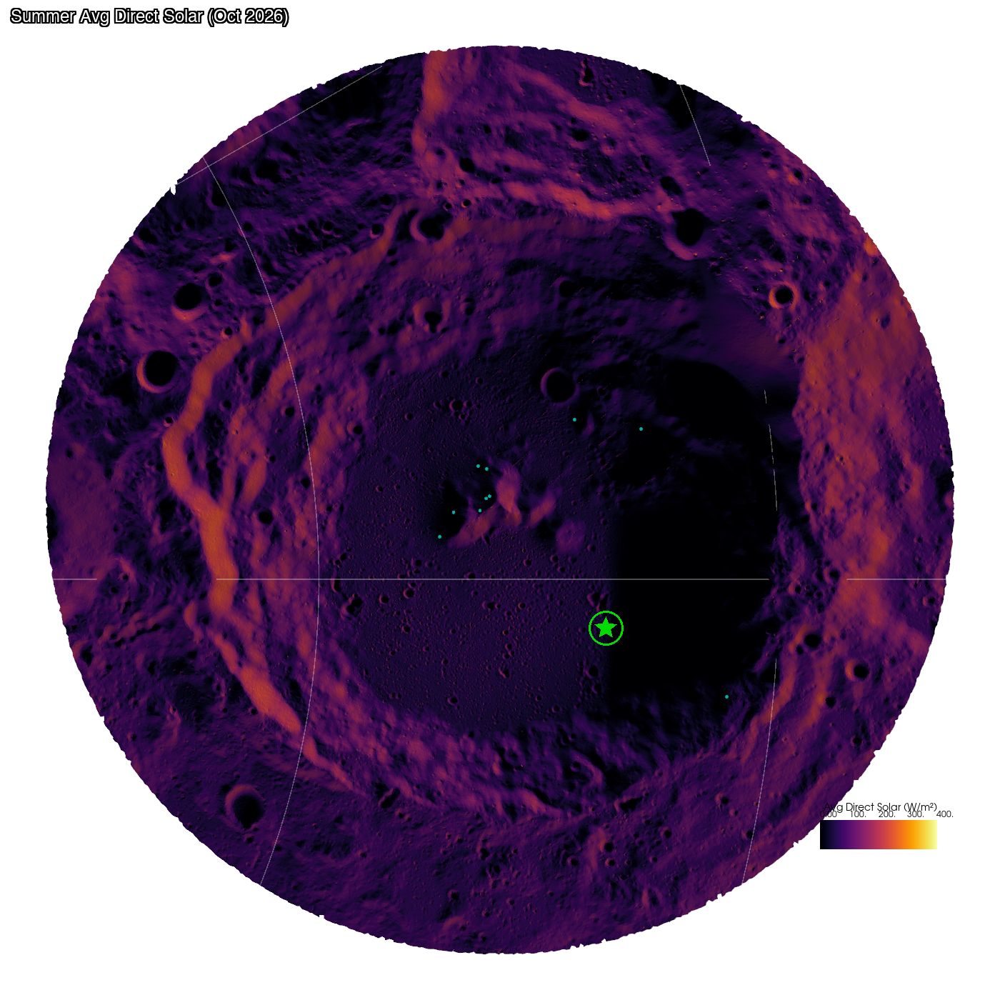

In [6]:
# --- Figure 2: Summer Direct Solar Flux (Stereographic) ---
pl = pv.Plotter(off_screen=True, window_size=[1400, 1400])
sp_mesh.cell_data['summer_solar'] = summer_solar
pl.add_mesh(sp_mesh, scalars='summer_solar', cmap='inferno', clim=[0, 400],
            scalar_bar_args={'title': 'Avg Direct Solar (W/m²)', 'color': 'black',
                             'title_font_size': 14, 'label_font_size': 12,
                             'position_x': 0.82, 'position_y': 0.15, 'width': 0.12},
            smooth_shading=False)
for loc in prime_targets[:10]:
    fi = loc['face_idx']
    pl.add_mesh(pv.Sphere(radius=300, center=(float(sp_x[fi]), float(sp_y[fi]), 300)),
                color='cyan', opacity=0.8)
add_latlon_grid(pl, color='white', opacity=0.3)
setup_stereo_view(pl, sp_mesh, sp_x, sp_y)
fig2_path = str(FIG_DIR / 'fig2_summer_illumination.png')
pl.screenshot(fig2_path)
pl.close()
annotate_grid_labels(fig2_path, sp_x, sp_y, text_color=(255,255,255),
    title="Summer Avg Direct Solar (Oct 2026)", title_color=(255,255,255))
display(IPImage(filename=fig2_path))

## 3. Summer vs. Winter Surface Temperature

Side-by-side comparison of average and maximum surface temperature during the summer lunation (left) and winter lunation (right). The average temperature shows the mean thermal state over a full lunation, while the maximum temperature reveals the peak daytime temperature — relevant for volatile stability assessment. Note the wider color scale for max T (25–350 K) vs avg T (25–250 K).

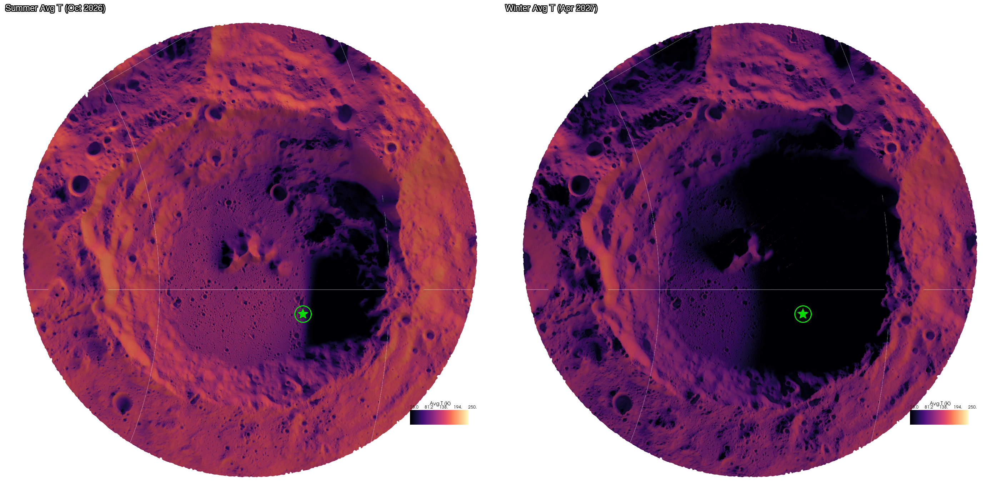

Saved: /Users/paha3326/Library/CloudStorage/OneDrive-UCB-O365/europa/heat3d/ptm/plots/amundsen_report/fig3_summer_winter_temp.png


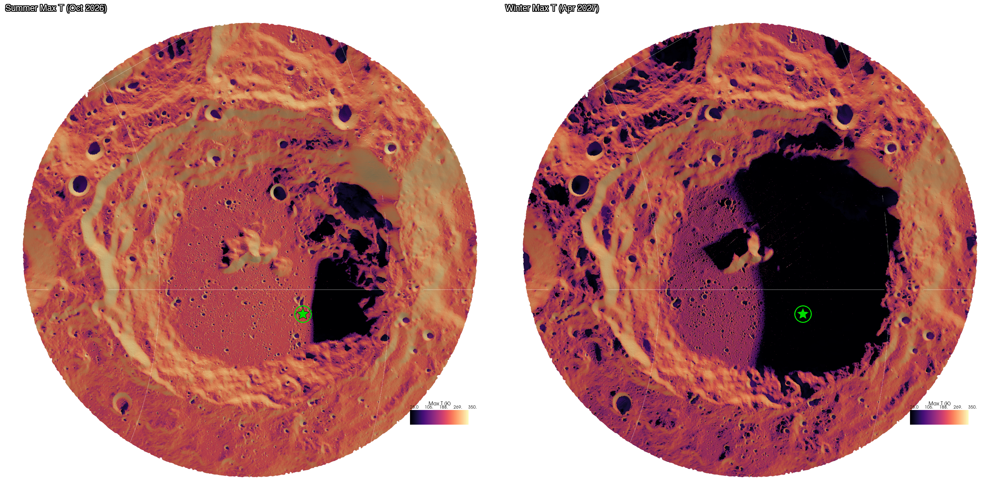

Saved: /Users/paha3326/Library/CloudStorage/OneDrive-UCB-O365/europa/heat3d/ptm/plots/amundsen_report/fig3_summer_winter_temp_max.png


In [7]:
# --- Figure 3: Summer vs Winter Temperature (Stereographic) ---
# Average temperature
for season, temp_data, label in [('summer', summer_temp, 'Summer Avg T (Oct 2026)'),
                                   ('winter', winter_temp, 'Winter Avg T (Apr 2027)')]:
    sp_tmp = sp_mesh.copy()
    sp_tmp.cell_data['temperature'] = temp_data
    pl = pv.Plotter(off_screen=True, window_size=[1400, 1400])
    pl.add_mesh(sp_tmp, scalars='temperature', cmap='magma', clim=[25, 250],
                scalar_bar_args={'title': 'Avg T (K)', 'color': 'black',
                                 'title_font_size': 14, 'label_font_size': 12,
                                 'position_x': 0.82, 'position_y': 0.15, 'width': 0.12},
                smooth_shading=False)
    add_latlon_grid(pl, color='white', opacity=0.3)
    setup_stereo_view(pl, sp_mesh, sp_x, sp_y)
    tmp_path = str(FIG_DIR / f'fig3_{season}_avg.png')
    pl.screenshot(tmp_path)
    pl.close()
    annotate_grid_labels(tmp_path, sp_x, sp_y, text_color=(255,255,255),
        title=label, title_color=(255,255,255))

# Combine avg side by side
from PIL import Image as PILImage
img_s = PILImage.open(str(FIG_DIR / 'fig3_summer_avg.png'))
img_w = PILImage.open(str(FIG_DIR / 'fig3_winter_avg.png'))
combined = PILImage.new('RGB', (img_s.width + img_w.width, img_s.height))
combined.paste(img_s, (0, 0))
combined.paste(img_w, (img_s.width, 0))
fig3_path = str(FIG_DIR / 'fig3_summer_winter_temp.png')
combined.save(fig3_path)
display(IPImage(filename=fig3_path))
print(f"Saved: {fig3_path}")

# Maximum temperature
summer_temp_max_data = read_stats_binary(str(THERMAL_DIR / "lunation_07/statistics/temperature_max.bin"))
winter_temp_max_data = read_stats_binary(str(THERMAL_DIR / "lunation_13/statistics/temperature_max.bin"))

for season, temp_data, label in [('summer', summer_temp_max_data, 'Summer Max T (Oct 2026)'),
                                   ('winter', winter_temp_max_data, 'Winter Max T (Apr 2027)')]:
    sp_tmp = sp_mesh.copy()
    sp_tmp.cell_data['temperature'] = temp_data
    pl = pv.Plotter(off_screen=True, window_size=[1400, 1400])
    pl.add_mesh(sp_tmp, scalars='temperature', cmap='magma', clim=[25, 350],
                scalar_bar_args={'title': 'Max T (K)', 'color': 'black',
                                 'title_font_size': 14, 'label_font_size': 12,
                                 'position_x': 0.82, 'position_y': 0.15, 'width': 0.12},
                smooth_shading=False)
    add_latlon_grid(pl, color='white', opacity=0.3)
    setup_stereo_view(pl, sp_mesh, sp_x, sp_y)
    tmp_path = str(FIG_DIR / f'fig3_{season}_max.png')
    pl.screenshot(tmp_path)
    pl.close()
    annotate_grid_labels(tmp_path, sp_x, sp_y, text_color=(255,255,255),
        title=label, title_color=(255,255,255))

img_s = PILImage.open(str(FIG_DIR / 'fig3_summer_max.png'))
img_w = PILImage.open(str(FIG_DIR / 'fig3_winter_max.png'))
combined_max = PILImage.new('RGB', (img_s.width + img_w.width, img_s.height))
combined_max.paste(img_s, (0, 0))
combined_max.paste(img_w, (img_s.width, 0))
fig3max_path = str(FIG_DIR / 'fig3_summer_winter_temp_max.png')
combined_max.save(fig3max_path)
display(IPImage(filename=fig3max_path))
print(f"Saved: {fig3max_path}")

## 4. Seasonal Illumination Pattern

The fraction of mesh faces receiving direct sunlight varies with a ~1-year period driven by the Moon's 1.54° obliquity. The black curve shows the overall illuminated fraction; the red curve shows the fraction of the 34 target locations that are illuminated in each lunation. The seasonal shadow targets transition from fully dark (winter) to partially illuminated (summer).

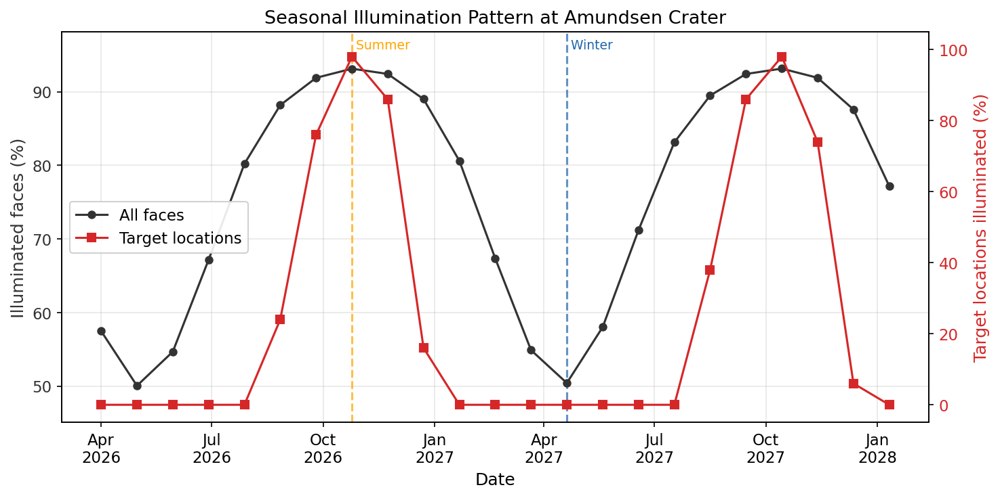

Saved: /Users/paha3326/Library/CloudStorage/OneDrive-UCB-O365/europa/heat3d/ptm/plots/amundsen_report/fig4_seasonal_pattern.png


In [8]:
# --- Figure 4: Seasonal Illumination Pattern ---
frac_all = np.zeros(NUM_LUNATIONS)
frac_targets = np.zeros(NUM_LUNATIONS)

for i in range(NUM_LUNATIONS):
    stats_file = SURVEY_DIR / f'lunation_{i:02d}/statistics/direct_solar_avg.bin'
    if not stats_file.exists():
        continue
    avg = read_stats_binary(str(stats_file))
    if len(avg) != nf:
        continue
    frac_all[i] = np.sum(avg > 0) / len(avg)
    n_lit = sum(1 for loc in locations if avg[loc['face_idx']] > 0.1)
    frac_targets[i] = n_lit / len(locations)

fig, ax1 = plt.subplots(figsize=(11, 5))

# All faces - left axis
color1 = '#333333'
ax1.plot(lunation_dates, frac_all * 100, 'o-', color=color1, ms=5, lw=1.5, label='All faces', zorder=3)
ax1.set_ylabel('Illuminated faces (%)', color=color1)
ax1.tick_params(axis='y', labelcolor=color1)

# Auto-scale with padding
y_min_all = max(0, frac_all.min() * 100 - 5)
y_max_all = min(100, frac_all.max() * 100 + 5)
ax1.set_ylim(y_min_all, y_max_all)

# Target locations - right axis
ax2 = ax1.twinx()
color2 = '#d62728'
ax2.plot(lunation_dates, frac_targets * 100, 's-', color=color2, ms=6, lw=1.5, label='Target locations', zorder=3)
ax2.set_ylabel('Target locations illuminated (%)', color=color2)
ax2.tick_params(axis='y', labelcolor=color2)
ax2.set_ylim(-5, 105)

# Season markers
ax1.axvline(lunation_dates[SUMMER_LUNATION], color='orange', ls='--', alpha=0.7, lw=1.5)
ax1.axvline(lunation_dates[WINTER_LUNATION], color='#2166ac', ls='--', alpha=0.7, lw=1.5)
ax1.text(lunation_dates[SUMMER_LUNATION], y_max_all - 1, ' Summer', color='orange', fontsize=9, va='top')
ax1.text(lunation_dates[WINTER_LUNATION], y_max_all - 1, ' Winter', color='#2166ac', fontsize=9, va='top')

ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
ax1.set_xlabel('Date')
ax1.set_title('Seasonal Illumination Pattern at Amundsen Crater')
ax1.grid(True, alpha=0.3)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center left', framealpha=0.9)

fig4_path = str(FIG_DIR / 'fig4_seasonal_pattern.png')
plt.savefig(fig4_path)
plt.show()
print(f"Saved: {fig4_path}")

## 5. Illumination Time Series at Selected Sites

Per-lunation average direct solar flux for 5 selected sites spanning different illumination regimes. Wilcoski's candidate site (-83.93°S, 92.51°E) is included. Each panel shows one lunation (~29.5 days) as a bar, with height proportional to the average flux received during that lunation. Zero bars indicate the site is in complete shadow for that lunation.

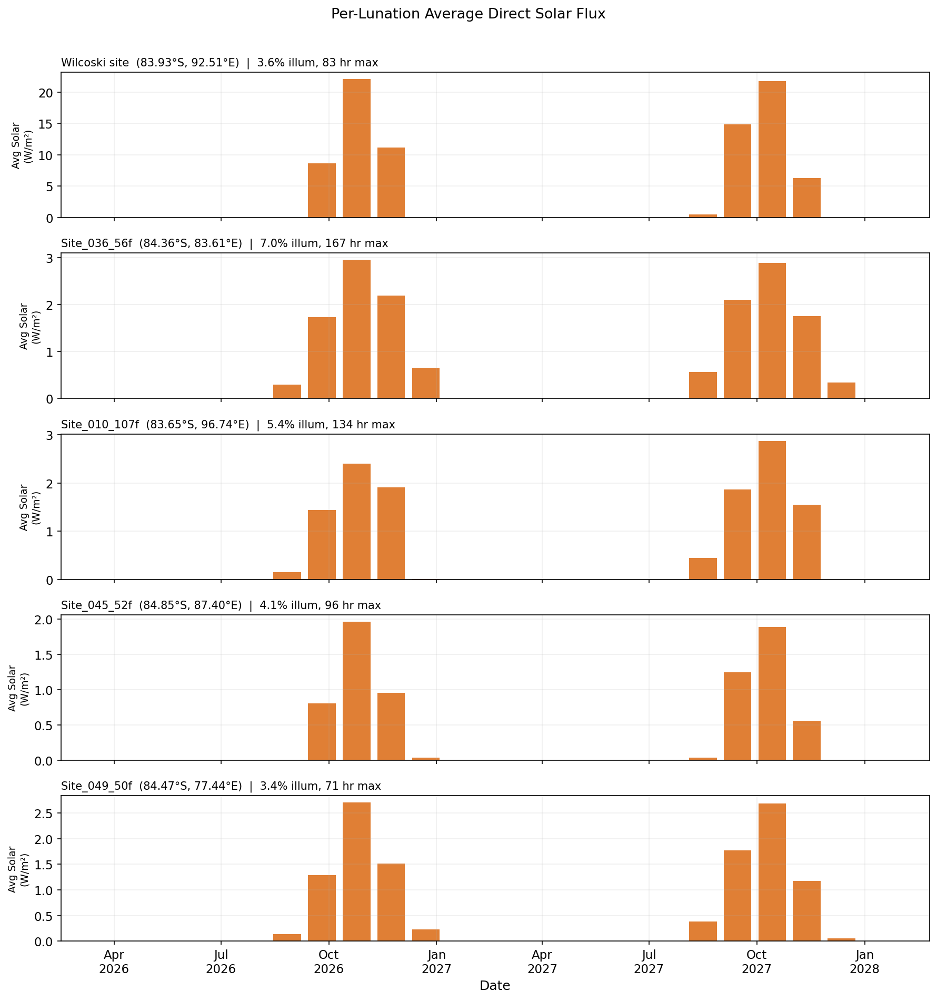

Saved: /Users/paha3326/Library/CloudStorage/OneDrive-UCB-O365/europa/heat3d/ptm/plots/amundsen_report/fig5_timeseries.png
Locations CSV updated: /Users/paha3326/Library/CloudStorage/OneDrive-UCB-O365/europa/heat3d/ptm/configs/amundsen_target_locations.csv


In [9]:
# --- Figure 5: Per-Lunation Illumination Time Series ---

# Define 5 sites for time series: Wilcoski's site + 4 distinct selected sites
wilcoski_lat, wilcoski_lon = -83.93341, 92.51474
wilcoski_fidx = int(np.argmin((latitudes - wilcoski_lat)**2 + (longitudes - wilcoski_lon)**2))

ts_sites = [
    {'name': 'Wilcoski site', 'face_idx': wilcoski_fidx,
     'lat': float(latitudes[wilcoski_fidx]), 'lon': float(longitudes[wilcoski_fidx])},
]

# Pick 4 from our selected locations: spread in lon and with varying illum fraction
used_lons = [wilcoski_lon]
for loc in sorted(locations, key=lambda x: x['max_cont_hrs'], reverse=True):
    if len(ts_sites) >= 5:
        break
    if all(abs(loc['lon'] - ul) > 3.0 for ul in used_lons):
        ts_sites.append({
            'name': loc['name'], 'face_idx': loc['face_idx'],
            'lat': loc['lat'], 'lon': loc['lon']
        })
        used_lons.append(loc['lon'])

for loc in locations:
    if len(ts_sites) >= 5:
        break
    if loc['face_idx'] not in [s['face_idx'] for s in ts_sites]:
        ts_sites.append({
            'name': loc['name'], 'face_idx': loc['face_idx'],
            'lat': loc['lat'], 'lon': loc['lon']
        })

# Build per-lunation flux time series for each site
site_flux = {s['name']: np.zeros(NUM_LUNATIONS) for s in ts_sites}

for i in range(NUM_LUNATIONS):
    avg_file = SURVEY_DIR / f'lunation_{i:02d}/statistics/direct_solar_avg.bin'
    if avg_file.exists():
        avg = read_stats_binary(str(avg_file))
        if len(avg) == nf:
            for s in ts_sites:
                site_flux[s['name']][i] = avg[s['face_idx']]

# Plot
fig, axes = plt.subplots(len(ts_sites), 1, figsize=(12, 2.5 * len(ts_sites)), sharex=True)
if len(ts_sites) == 1:
    axes = [axes]

bar_width = timedelta(days=LUNATION_DAYS * 0.8)
for ax, site in zip(axes, ts_sites):
    flux = site_flux[site['name']]
    colors = ['#d95f02' if f > 0 else '#2166ac' for f in flux]
    ax.bar(lunation_dates, flux, width=bar_width, color=colors, edgecolor='none', alpha=0.8)
    ax.set_ylabel('Avg Solar\n(W/m²)', fontsize=9)

    frac = illum_fraction[site['face_idx']]
    cont = max_continuous_hours[site['face_idx']]
    label = f"{site['name']}  ({abs(site['lat']):.2f}°S, {site['lon']:.2f}°E)"
    label += f"  |  {frac*100:.1f}% illum, {cont:.0f} hr max"
    ax.set_title(label, fontsize=10, loc='left')
    ax.grid(True, alpha=0.2)
    ax.set_ylim(bottom=0)

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
axes[-1].set_xlabel('Date')
fig.suptitle('Per-Lunation Average Direct Solar Flux', fontsize=13, y=1.01)
plt.tight_layout()

fig5_path = str(FIG_DIR / 'fig5_timeseries.png')
plt.savefig(fig5_path)
plt.show()
print(f"Saved: {fig5_path}")

# Write the new locations CSV including Wilcoski's site
loc_csv_path = BASE / "configs" / "amundsen_target_locations.csv"
with open(loc_csv_path, 'w') as f:
    f.write("# Amundsen crater observation targets\n")
    f.write(f"# Selection: illum {MIN_ILLUM_FRACTION*100:.2f}-{MAX_ILLUM_FRACTION*100:.0f}%, "
            f"cont >= {MIN_CONTINUOUS_HOURS:.0f} hr, T_max < {MAX_TEMPERATURE_K:.0f} K\n")
    f.write(f"# Includes Wilcoski candidate site at -83.93S, 92.51E\n")
    f.write(f"Wilcoski_site,{wilcoski_lat:.6f},{wilcoski_lon:.6f}\n")
    for loc in locations:
        f.write(f"{loc['name']},{loc['lat']:.6f},{loc['lon']:.6f}\n")
print(f"Locations CSV updated: {loc_csv_path}")

## 6. Temperature Distribution: Summer vs. Winter

Histograms of surface temperature at all 34 target locations during the summer lunation (orange) and winter lunation (blue). The dashed line at 110 K marks the approximate threshold for water ice thermal stability (sublimation rate exceeds 1 mm/Gyr). During winter, most targets are below this threshold; during summer, the distribution is bimodal — some targets receive direct sunlight and warm to >200 K while others remain in shadow.

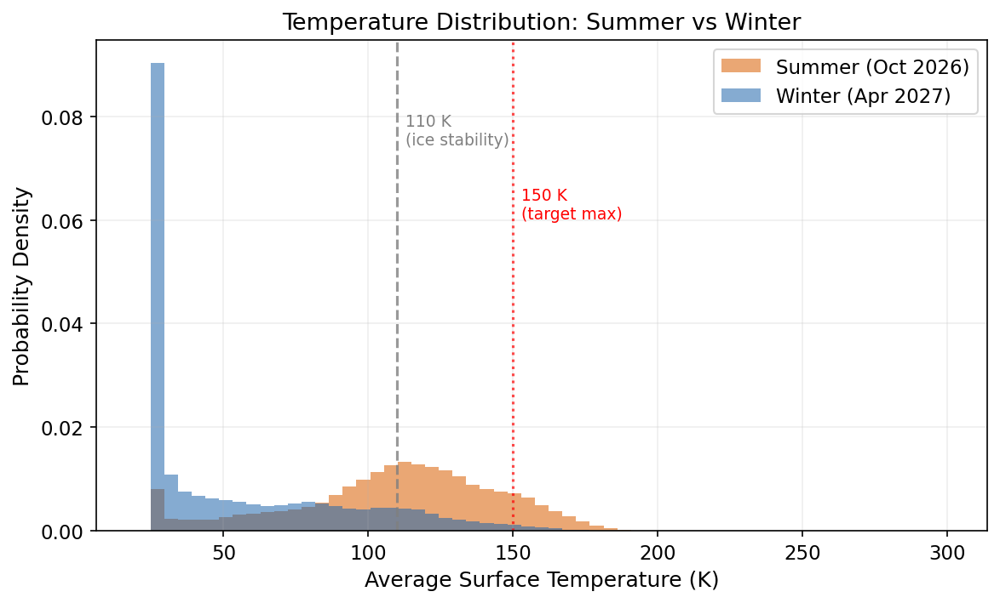

Saved: /Users/paha3326/Library/CloudStorage/OneDrive-UCB-O365/europa/heat3d/ptm/plots/amundsen_report/fig6_temp_histogram.png


In [10]:
# --- Figure 6: Temperature Histograms (from per-face statistics) ---
fig, ax = plt.subplots(figsize=(9, 5))
bins = np.linspace(20, 300, 60)

# Use per-face avg temp from summer and winter statistics
summer_t = summer_temp[summer_temp > 1]
winter_t = winter_temp[winter_temp > 1]

ax.hist(summer_t, bins=bins, alpha=0.55, color='#d95f02', label='Summer (Oct 2026)',
        density=True, edgecolor='none')
ax.hist(winter_t, bins=bins, alpha=0.55, color='#2166ac', label='Winter (Apr 2027)',
        density=True, edgecolor='none')

ax.axvline(110, color='gray', ls='--', lw=1.5, alpha=0.8)
ax.text(113, ax.get_ylim()[1]*0.85, '110 K\n(ice stability)', fontsize=9, color='gray', va='top')
ax.axvline(MAX_TEMPERATURE_K, color='red', ls=':', lw=1.5, alpha=0.7)
ax.text(MAX_TEMPERATURE_K+3, ax.get_ylim()[1]*0.7, f'{MAX_TEMPERATURE_K:.0f} K\n(target max)',
        fontsize=9, color='red', va='top')

ax.set_xlabel('Average Surface Temperature (K)')
ax.set_ylabel('Probability Density')
ax.set_title('Temperature Distribution: Summer vs Winter')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.2)

fig6_path = str(FIG_DIR / 'fig6_temp_histogram.png')
plt.savefig(fig6_path)
plt.show()
print(f"Saved: {fig6_path}")

## 8. Illumination Time Distribution

Histogram of the fraction of total time each face is illuminated over the 2-year survey, accounting for both the seasonal cycle and the diurnal cycle. For each lunation, the illuminated time fraction is estimated as avg_flux / max_flux (the fraction of timesteps with nonzero direct solar). The overall fraction is the mean across all 25 lunations.

PSR faces have 0% illumination. Most crater floor faces are illuminated ~15–25% of the total time (lit during daytime for roughly half the lunations). The targets occupy the low end of this distribution.

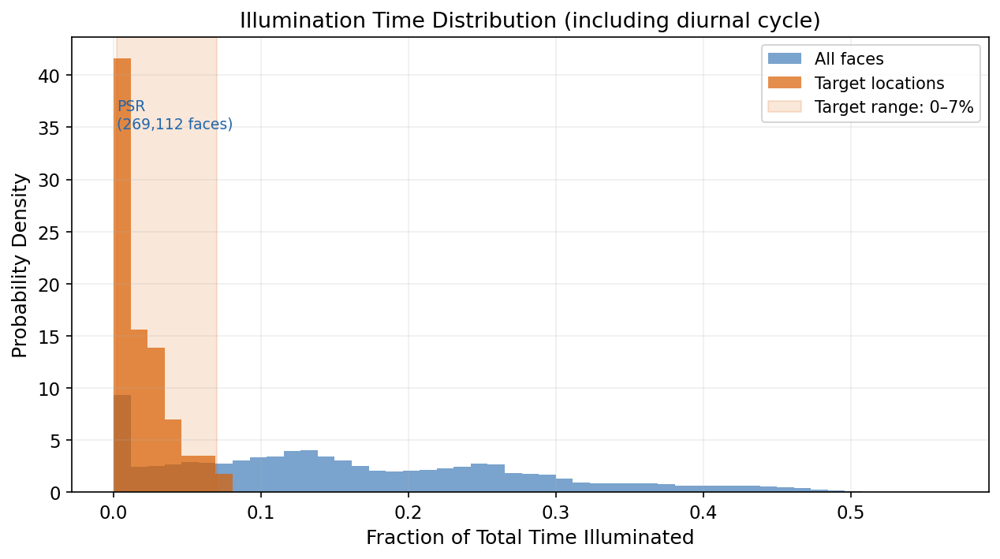

Saved: /Users/paha3326/Library/CloudStorage/OneDrive-UCB-O365/europa/heat3d/ptm/plots/amundsen_report/fig8_illum_time_histogram.png
Illumination fraction stats:
  All faces: mean=16.0%, max=53.8%
  Targets: mean=2.0%, range=0.2–7.0%


In [11]:
# --- Figure 8: Illumination Time Distribution (corrected for diurnal cycle) ---
fig, ax = plt.subplots(figsize=(10, 5))

bins = np.linspace(0, illum_fraction.max() * 1.05, 50)

# Full mesh
ax.hist(illum_fraction, bins=bins, alpha=0.6, color='#2166ac', label='All faces',
        density=True, edgecolor='none')

# Target locations only
target_fracs = np.array([illum_fraction[loc['face_idx']] for loc in locations])
ax.hist(target_fracs, bins=bins, alpha=0.7, color='#d95f02', label='Target locations',
        density=True, edgecolor='none')

ax.set_xlabel('Fraction of Total Time Illuminated')
ax.set_ylabel('Probability Density')
ax.set_title('Illumination Time Distribution (including diurnal cycle)')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.2)

# Annotate
psr_frac_count = np.sum(illum_fraction == 0)
ax.annotate(f'PSR\n({psr_frac_count:,} faces)', xy=(0.002, ax.get_ylim()[1]*0.8),
            fontsize=9, color='#2166ac', ha='left')

# Mark target range
if len(target_fracs) > 0:
    ax.axvspan(target_fracs.min(), target_fracs.max(), alpha=0.15, color='#d95f02',
               label=f'Target range: {target_fracs.min()*100:.0f}–{target_fracs.max()*100:.0f}%')
    ax.legend(fontsize=10)

fig8_path = str(FIG_DIR / 'fig8_illum_time_histogram.png')
plt.savefig(fig8_path)
plt.show()
print(f"Saved: {fig8_path}")
print(f"Illumination fraction stats:")
print(f"  All faces: mean={illum_fraction.mean()*100:.1f}%, max={illum_fraction.max()*100:.1f}%")
print(f"  Targets: mean={target_fracs.mean()*100:.1f}%, range={target_fracs.min()*100:.1f}–{target_fracs.max()*100:.1f}%")

## Target Summary Table

Selected sites meeting all criteria: illumination fraction 0.01–20%, continuous illumination ≥ 8 hr, T_max < 150 K.

In [12]:
# --- Target Summary Table ---
rows = []
for loc in locations:
    rows.append({
        'Site': loc['name'],
        'Lat (°S)': f"{abs(loc['lat']):.2f}",
        'Lon (°E)': f"{loc['lon']:.2f}",
        'Illum (%)': f"{loc['illum_frac']*100:.1f}",
        'Max Cont. (hr)': f"{loc['max_cont_hrs']:.0f}",
        'Summer T_max (K)': f"{loc['summer_tmax']:.0f}",
        'Cluster Size': f"{loc['cluster_size']:,}",
    })

df_table = pd.DataFrame(rows)
df_table.style.hide(axis='index')

Site,Lat (°S),Lon (°E),Illum (%),Max Cont. (hr),Summer T_max (K),Cluster Size
Site_000_188f,84.60,83.44,2.6,61,144,188
Site_001_165f,83.25,95.44,5.7,128,145,165
Site_002_158f,84.75,86.00,0.7,30,149,158
Site_003_147f,84.61,86.02,1.8,53,139,147
Site_004_146f,84.55,85.23,1.0,35,149,146
Site_005_142f,84.05,81.60,2.0,55,144,142
Site_006_133f,84.84,87.42,1.3,41,118,133
Site_007_130f,84.57,85.35,0.8,31,141,130
Site_008_129f,83.69,82.54,0.2,18,136,129
Site_009_108f,84.55,83.66,3.2,61,148,108


## 9. Illumination/Shadow Timing for Observation Planning

UTC start and end times for illuminated and shadowed intervals at each target location. Derived from the 25-lunation survey: a target transitions from "shadow" to "illuminated" when it first receives direct sunlight in a given lunation, and vice versa. Times are approximate to the lunation boundary (~29.5 day resolution).

In [13]:
# --- Table: Illumination/Shadow Timing (with merged site cells) ---
# Include Wilcoski's site in the timing analysis
all_timing_sites = [
    {'name': 'Wilcoski site', 'face_idx': wilcoski_fidx,
     'lat': wilcoski_lat, 'lon': wilcoski_lon}
] + [{'name': l['name'], 'face_idx': l['face_idx'], 'lat': l['lat'], 'lon': l['lon']}
     for l in locations]

rows = []
for loc in all_timing_sites:
    states = []
    for i in range(NUM_LUNATIONS):
        stats_file = SURVEY_DIR / f'lunation_{i:02d}/statistics/direct_solar_avg.bin'
        if stats_file.exists():
            avg = read_stats_binary(str(stats_file))
            states.append(len(avg) == nf and avg[loc['face_idx']] > 0)
        else:
            states.append(False)

    name = loc['name']
    lit_start = dark_start = None
    windows = []
    for i in range(NUM_LUNATIONS):
        if states[i] and lit_start is None:
            lit_start = i
            if dark_start is not None:
                windows.append(('Shadow', lunation_dates[dark_start].strftime('%Y-%m-%d'),
                                lunation_dates[i].strftime('%Y-%m-%d'), i - dark_start))
                dark_start = None
        elif not states[i] and dark_start is None:
            dark_start = i
            if lit_start is not None:
                windows.append(('Illuminated', lunation_dates[lit_start].strftime('%Y-%m-%d'),
                                lunation_dates[i].strftime('%Y-%m-%d'), i - lit_start))
                lit_start = None
    end_date = (lunation_dates[-1] + timedelta(days=LUNATION_DAYS)).strftime('%Y-%m-%d')
    if lit_start is not None:
        windows.append(('Illuminated', lunation_dates[lit_start].strftime('%Y-%m-%d'),
                        end_date, NUM_LUNATIONS - lit_start))
    if dark_start is not None:
        windows.append(('Shadow', lunation_dates[dark_start].strftime('%Y-%m-%d'),
                        end_date, NUM_LUNATIONS - dark_start))

    for w in windows:
        rows.append({
            'Site': name,
            'Lat (°S)': f"{abs(loc['lat']):.2f}",
            'Lon (°E)': f"{loc['lon']:.2f}",
            'State': w[0],
            'Start (UTC)': w[1],
            'End (UTC)': w[2],
            'Duration (lunations)': w[3],
        })

df_timing = pd.DataFrame(rows)

# Build HTML with merged site name cells using rowspan
html_parts = ['<table border="1" style="border-collapse:collapse; font-size:12px;">']
html_parts.append('<tr style="background:#ddd; font-weight:bold;">')
for col in ['Site', 'Lat (°S)', 'Lon (°E)', 'State', 'Start (UTC)', 'End (UTC)', 'Duration']:
    html_parts.append(f'<th style="padding:4px 8px;">{col}</th>')
html_parts.append('</tr>')

site_groups = df_timing.groupby('Site', sort=False)
for site_name, group in site_groups:
    n_rows = len(group)
    for idx, (_, row) in enumerate(group.iterrows()):
        bg = '#fff9e6' if row['State'] == 'Illuminated' else '#e6f0ff'
        html_parts.append(f'<tr style="background:{bg};">')
        if idx == 0:
            html_parts.append(f'<td rowspan="{n_rows}" style="padding:4px 8px; vertical-align:middle; font-weight:bold;">{row["Site"]}</td>')
            html_parts.append(f'<td rowspan="{n_rows}" style="padding:4px 8px; vertical-align:middle;">{row["Lat (°S)"]}</td>')
            html_parts.append(f'<td rowspan="{n_rows}" style="padding:4px 8px; vertical-align:middle;">{row["Lon (°E)"]}</td>')
        html_parts.append(f'<td style="padding:4px 8px;">{row["State"]}</td>')
        html_parts.append(f'<td style="padding:4px 8px;">{row["Start (UTC)"]}</td>')
        html_parts.append(f'<td style="padding:4px 8px;">{row["End (UTC)"]}</td>')
        html_parts.append(f'<td style="padding:4px 8px; text-align:center;">{row["Duration (lunations)"]}</td>')
        html_parts.append('</tr>')

html_parts.append('</table>')
from IPython.display import HTML
HTML('\n'.join(html_parts))

## Discussion

### Observation Planning

The prime targets identified above are ideal for Diviner observations because:

1. **Timing is predictable**: Direct solar illumination windows occur during the summer season (roughly lunations 4–10 of each cycle, corresponding to Jul–Dec 2026 and Jul–Dec 2027). The time series data provides precise UTC timing for each target.

2. **Temperature contrast is large**: The seasonal temperature swing at prime targets enables measuring the thermal response as a function of illumination state — a direct constraint on regolith thermal inertia at the PSR margin.

3. **Indirect flux is measurable**: Even during the dark season, scattered radiation from illuminated crater walls provides a small but non-negligible heat source (0.01–10 W/m²). This indirect heating raises temperatures above the purely radiative equilibrium value and could be compared to Diviner nighttime observations.

4. **Cluster sizes are Diviner-resolvable**: The identified clusters span hundreds to thousands of 20-m faces (surface areas of 0.1–1+ km²), well within Diviner's spatial resolution.

### Model Notes

- Illumination computed via SPICE ephemeris (IAU_MOON frame) with Embree ray tracing on the full 4M-face DEM mesh.
- Thermal model: two-layer regolith (surface k = 0.74 mW/m/K, deep k = 3.4 mW/m/K) with 1 lunation equilibration per run.
- Radiation exchange: H-matrix compressed view factors with 3 coupling iterations per thermal run.
- The DEM is derived from LOLA 20 m/pixel polar stereographic data (LDEM_80S_20M), triangulated with adaptive radial refinement (~2M vertices).

## Data Products

| File | Description |
|------|-------------|
| `configs/amundsen_target_locations.csv` | Target locations (name, lat, lon) for observation planning |
| `output/thermal/amundsen_seasonal_timeseries.csv` | Time series: DirectSolar, PrimaryReflected, PrimaryIR, IndirectFlux, Temperature per location |
| `output/survey/face_classification.bin` | Per-face classification (0=PSR, 1=seasonal, 2=always-lit) |
| `output/thermal/lunation_07/statistics/*.bin` | Summer per-face statistics (avg/min/max) |
| `output/thermal/lunation_13/statistics/*.bin` | Winter per-face statistics |

---
*Generated with PTM3D from `src/python/notebooks/amundsen_seasonal_shadow.ipynb`*